**Improt Libaraies**

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Bidirectional, LSTM, Dense, Dropout, MultiHeadAttention, LayerNormalization, Add)
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import seaborn as sns
from keras.utils import plot_model
from sklearn.metrics import roc_curve, auc

# Reproducibility: seed 42 for Python, NumPy and TensorFlow (weight initialization and training)
tf.keras.utils.set_random_seed(42)


In [ ]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
import os
out_dir = '/content/gdrive/MyDrive/IoT_outputs'
os.makedirs(out_dir, exist_ok=True)

In [ ]:
df = pd.read_csv('/content/gdrive/MyDrive/CIC_IOT_2023.csv')
df.shape

(350084, 47)

In [ ]:
targets = {'BruteForce': 29454, 'Web': 58954}
parts = [df]
for fam, n_target in targets.items():
    fam_df = df[df['label'] == fam]
    parts.append(fam_df.sample(n=n_target - len(fam_df), replace=True, random_state=42))
df = pd.concat(parts).sample(frac=1.0, random_state=42).reset_index(drop=True)

expected = {'BruteForce': 29454, 'DDoS': 53833, 'DoS': 70106, 'Mirai': 47218,
            'Recon': 43890, 'Spoofing': 46629, 'Web': 58954}
if df['label'].dtype == object:
    assert df['label'].value_counts().to_dict() == expected, "Class counts differ from Table 1"
assert len(df) == 350084 and df.shape[1] == 47, "Dataset shape differs from the manuscript (350,084 x 46 features + label)"

**Data  Analysis**

In [ ]:
df.isnull().sum()

,0
flow_duration,0
Header_Length,0
Protocol Type,0
Duration,0
Rate,0
Srate,0
Drate,0
fin_flag_number,0
syn_flag_number,0
rst_flag_number,0


In [ ]:
df.head(10)

,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,185.030991,2.717320e+04,9.300000,140.000000,2.669988,2.669988,0,0,0,0,...,42.482965,111.800000,1.666014e+08,13.5,12.858919,60.025903,1.858906e+03,1.000000,244.60,BruteForce
1,49.611279,3.334392e+06,7.091466,217.479052,69.522387,69.522387,0,0,0,0,...,47.950208,225.949316,1.442564e-03,5.5,12.612047,67.811835,1.875643e+04,0.198448,38.50,DDoS
2,367.518567,1.730799e+03,10.307661,125.800179,15.559048,15.559048,0,0,0,0,...,23.300649,113.640772,1.784168e-02,5.5,15.215357,32.952094,6.891856e+02,0.869803,38.50,DoS
3,2.774206,9.119005e+04,8.938445,86.296285,57.528605,57.528605,0,0,0,0,...,769.705110,887.983735,7.437150e-03,5.5,31.535327,1088.527405,1.120499e+06,0.900000,38.50,DDoS
4,0.000000,0.000000e+00,47.000000,64.000000,58.640196,58.640196,0,0,0,0,...,0.000000,592.000000,8.369374e+07,9.5,34.409301,0.000000,0.000000e+00,0.000000,141.55,Mirai
5,43.612811,5.437072e+05,10.000000,124.100000,40.989525,40.989525,0,0,0,0,...,6.048498,60.000000,5.507803e-03,5.5,10.915009,8.553868,4.102081e+01,0.900000,38.50,DDoS
6,0.000000,0.000000e+00,47.000000,64.000000,19.545649,19.545649,0,0,0,0,...,0.000000,578.000000,8.365090e+07,9.5,34.000000,0.000000,0.000000e+00,0.000000,141.55,Mirai
7,0.000000,5.800000e+01,6.000000,49.382913,18.407799,18.407799,0,0,1,0,...,0.000000,58.000000,2.180000e-05,5.5,10.770330,0.000000,0.000000e+00,0.000000,38.50,Recon
8,1.954996,5.807330e+04,7.600000,68.700000,47.085954,47.085954,0,0,0,0,...,46.700400,75.000000,2.479815e-03,5.5,13.052338,66.044339,2.506379e+03,0.900000,38.50,Web
9,0.000000,5.400000e+01,6.000000,64.000000,0.441344,0.441344,0,0,1,0,...,0.000000,54.000000,8.308996e+07,9.5,10.392305,0.000000,0.000000e+00,0.000000,141.55,DoS


In [ ]:
df.describe()

,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,AVG,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight
count,350084.000000,3.500840e+05,350084.000000,350084.000000,3.500840e+05,3.500840e+05,350084.0,350084.000000,350084.000000,350084.000000,...,350084.000000,350084.000000,350084.000000,3.500840e+05,350084.000000,350084.000000,350084.000000,3.500840e+05,350084.000000,350084.000000
mean,124.339460,5.551630e+05,11.673425,89.874981,1.616805e+04,1.616805e+04,0.0,0.017973,0.063125,0.030667,...,418.871171,212.617039,423.550184,5.754226e+07,8.261291,23.685714,300.498075,2.495659e+05,0.549929,109.634515
std,1208.083106,1.256745e+06,11.164552,39.449744,1.492109e+05,1.492109e+05,0.0,0.132853,0.243188,0.172414,...,567.041866,410.600608,560.858731,6.238421e+07,2.994151,15.757506,580.858743,1.058512e+06,0.413940,77.104815
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.0,0.000000,0.000000,0.000000,...,42.000000,0.000000,42.000000,0.000000e+00,1.000000,9.165151,0.000000,0.000000e+00,0.000000,1.000000
25%,0.042346,1.080000e+02,6.000000,64.000000,8.585118e+00,8.585118e+00,0.0,0.000000,0.000000,0.000000,...,63.622869,0.279421,64.750539,8.325034e-03,5.500000,11.242773,0.356536,9.512008e-01,0.035168,38.500000
50%,5.614385,1.893245e+04,7.100000,69.900000,3.929662e+01,3.929662e+01,0.0,0.000000,0.000000,0.000000,...,130.134051,38.225699,131.781899,8.295610e+07,9.500000,15.943573,53.892862,2.589826e+03,0.800000,141.550000
75%,52.690727,4.334516e+05,12.400259,105.672251,1.735904e+02,1.735904e+02,0.0,0.000000,0.000000,0.000000,...,578.000000,196.987454,578.000000,8.367763e+07,9.500000,33.867992,277.713928,6.723481e+04,0.900000,141.550000
max,99685.656390,9.831391e+06,47.000000,255.000000,3.145728e+06,3.145728e+06,0.0,1.000000,1.000000,1.000000,...,11650.000000,12385.239100,11650.000000,1.676394e+08,15.000000,152.643375,17551.270810,1.549022e+08,1.000000,244.600000


In [ ]:
#checking count of classifications
df['label'].value_counts()

,count
label,
DoS,70106
Web,58954
DDoS,53833
Mirai,47218
Spoofing,46629
Recon,43890
BruteForce,29454


/tmp/ipykernel_26736/3193138244.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label',data=df, palette='PuBuGn')


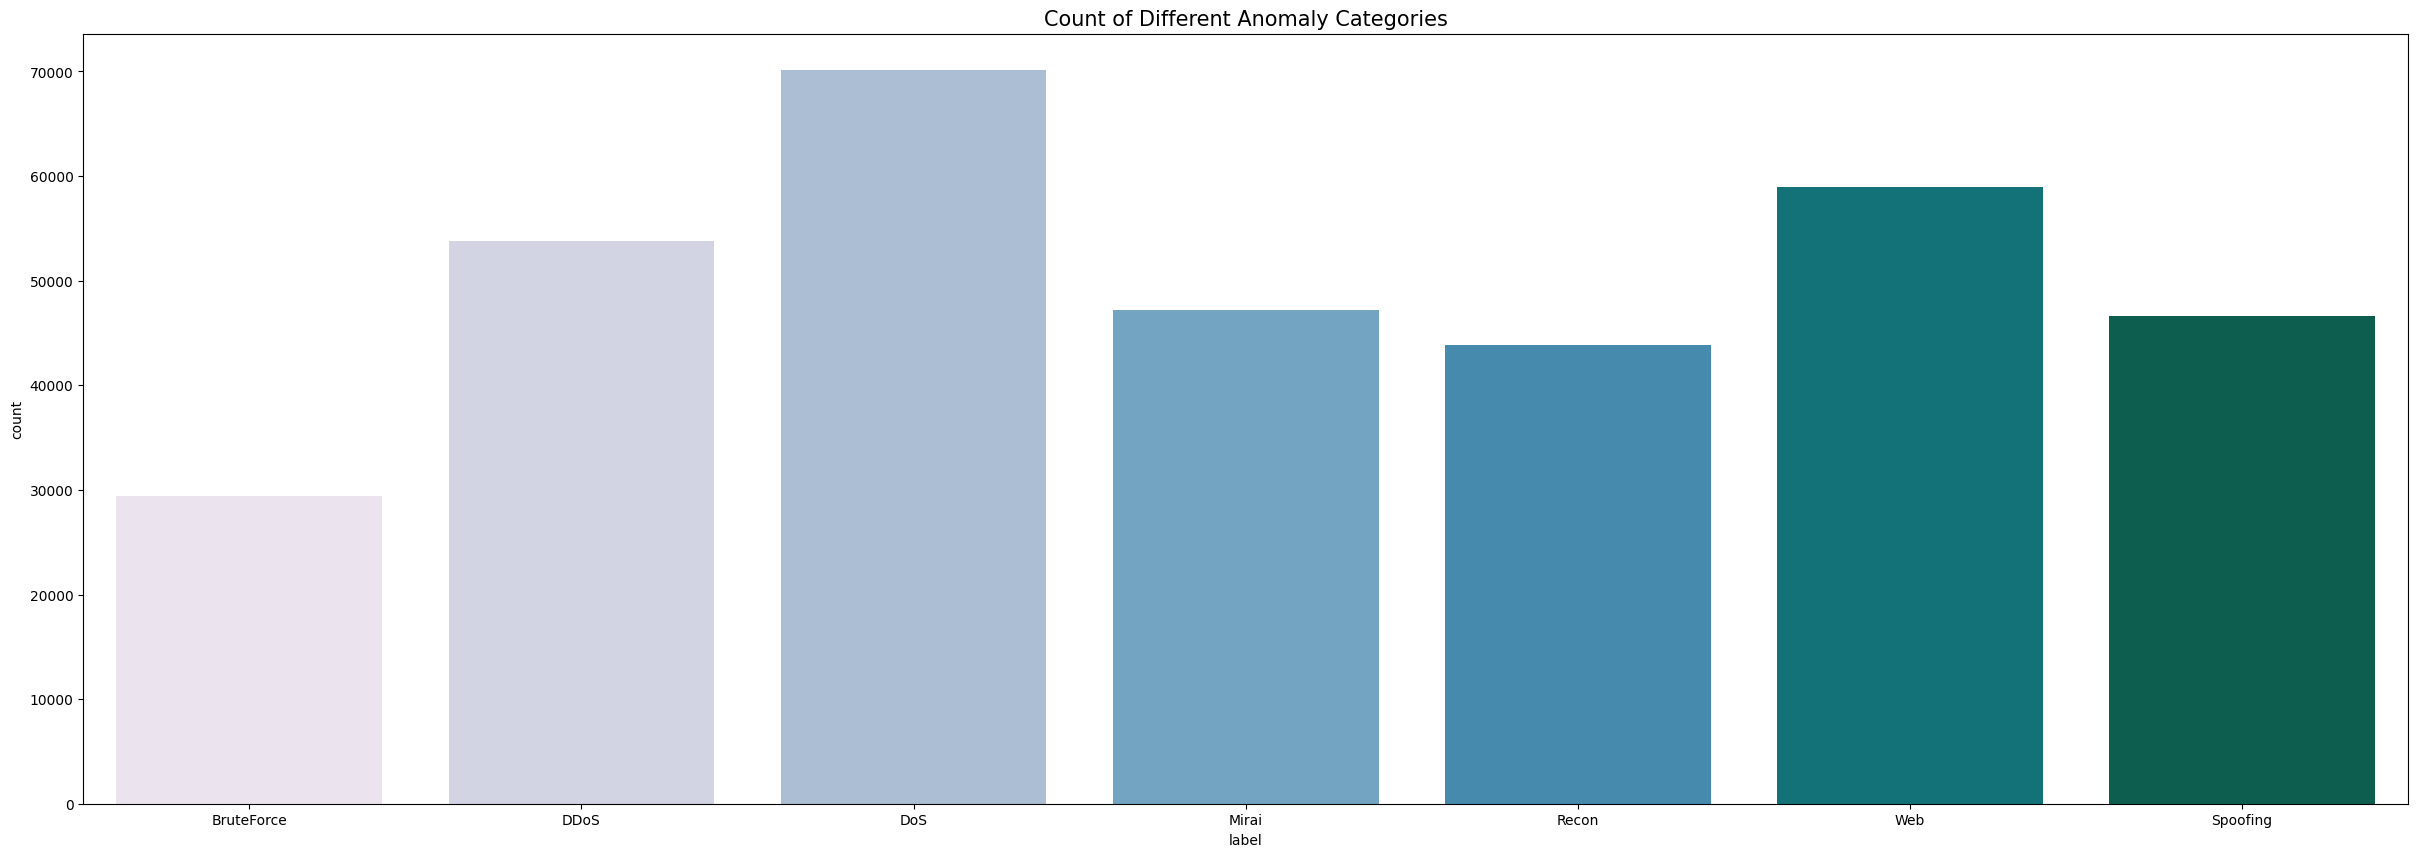

In [ ]:
plt.figure(figsize=(30,10))
sns.countplot(x='label',data=df, palette='PuBuGn')
plt.title('Count of Different Anomaly Categories', fontsize=15)
plt.show()

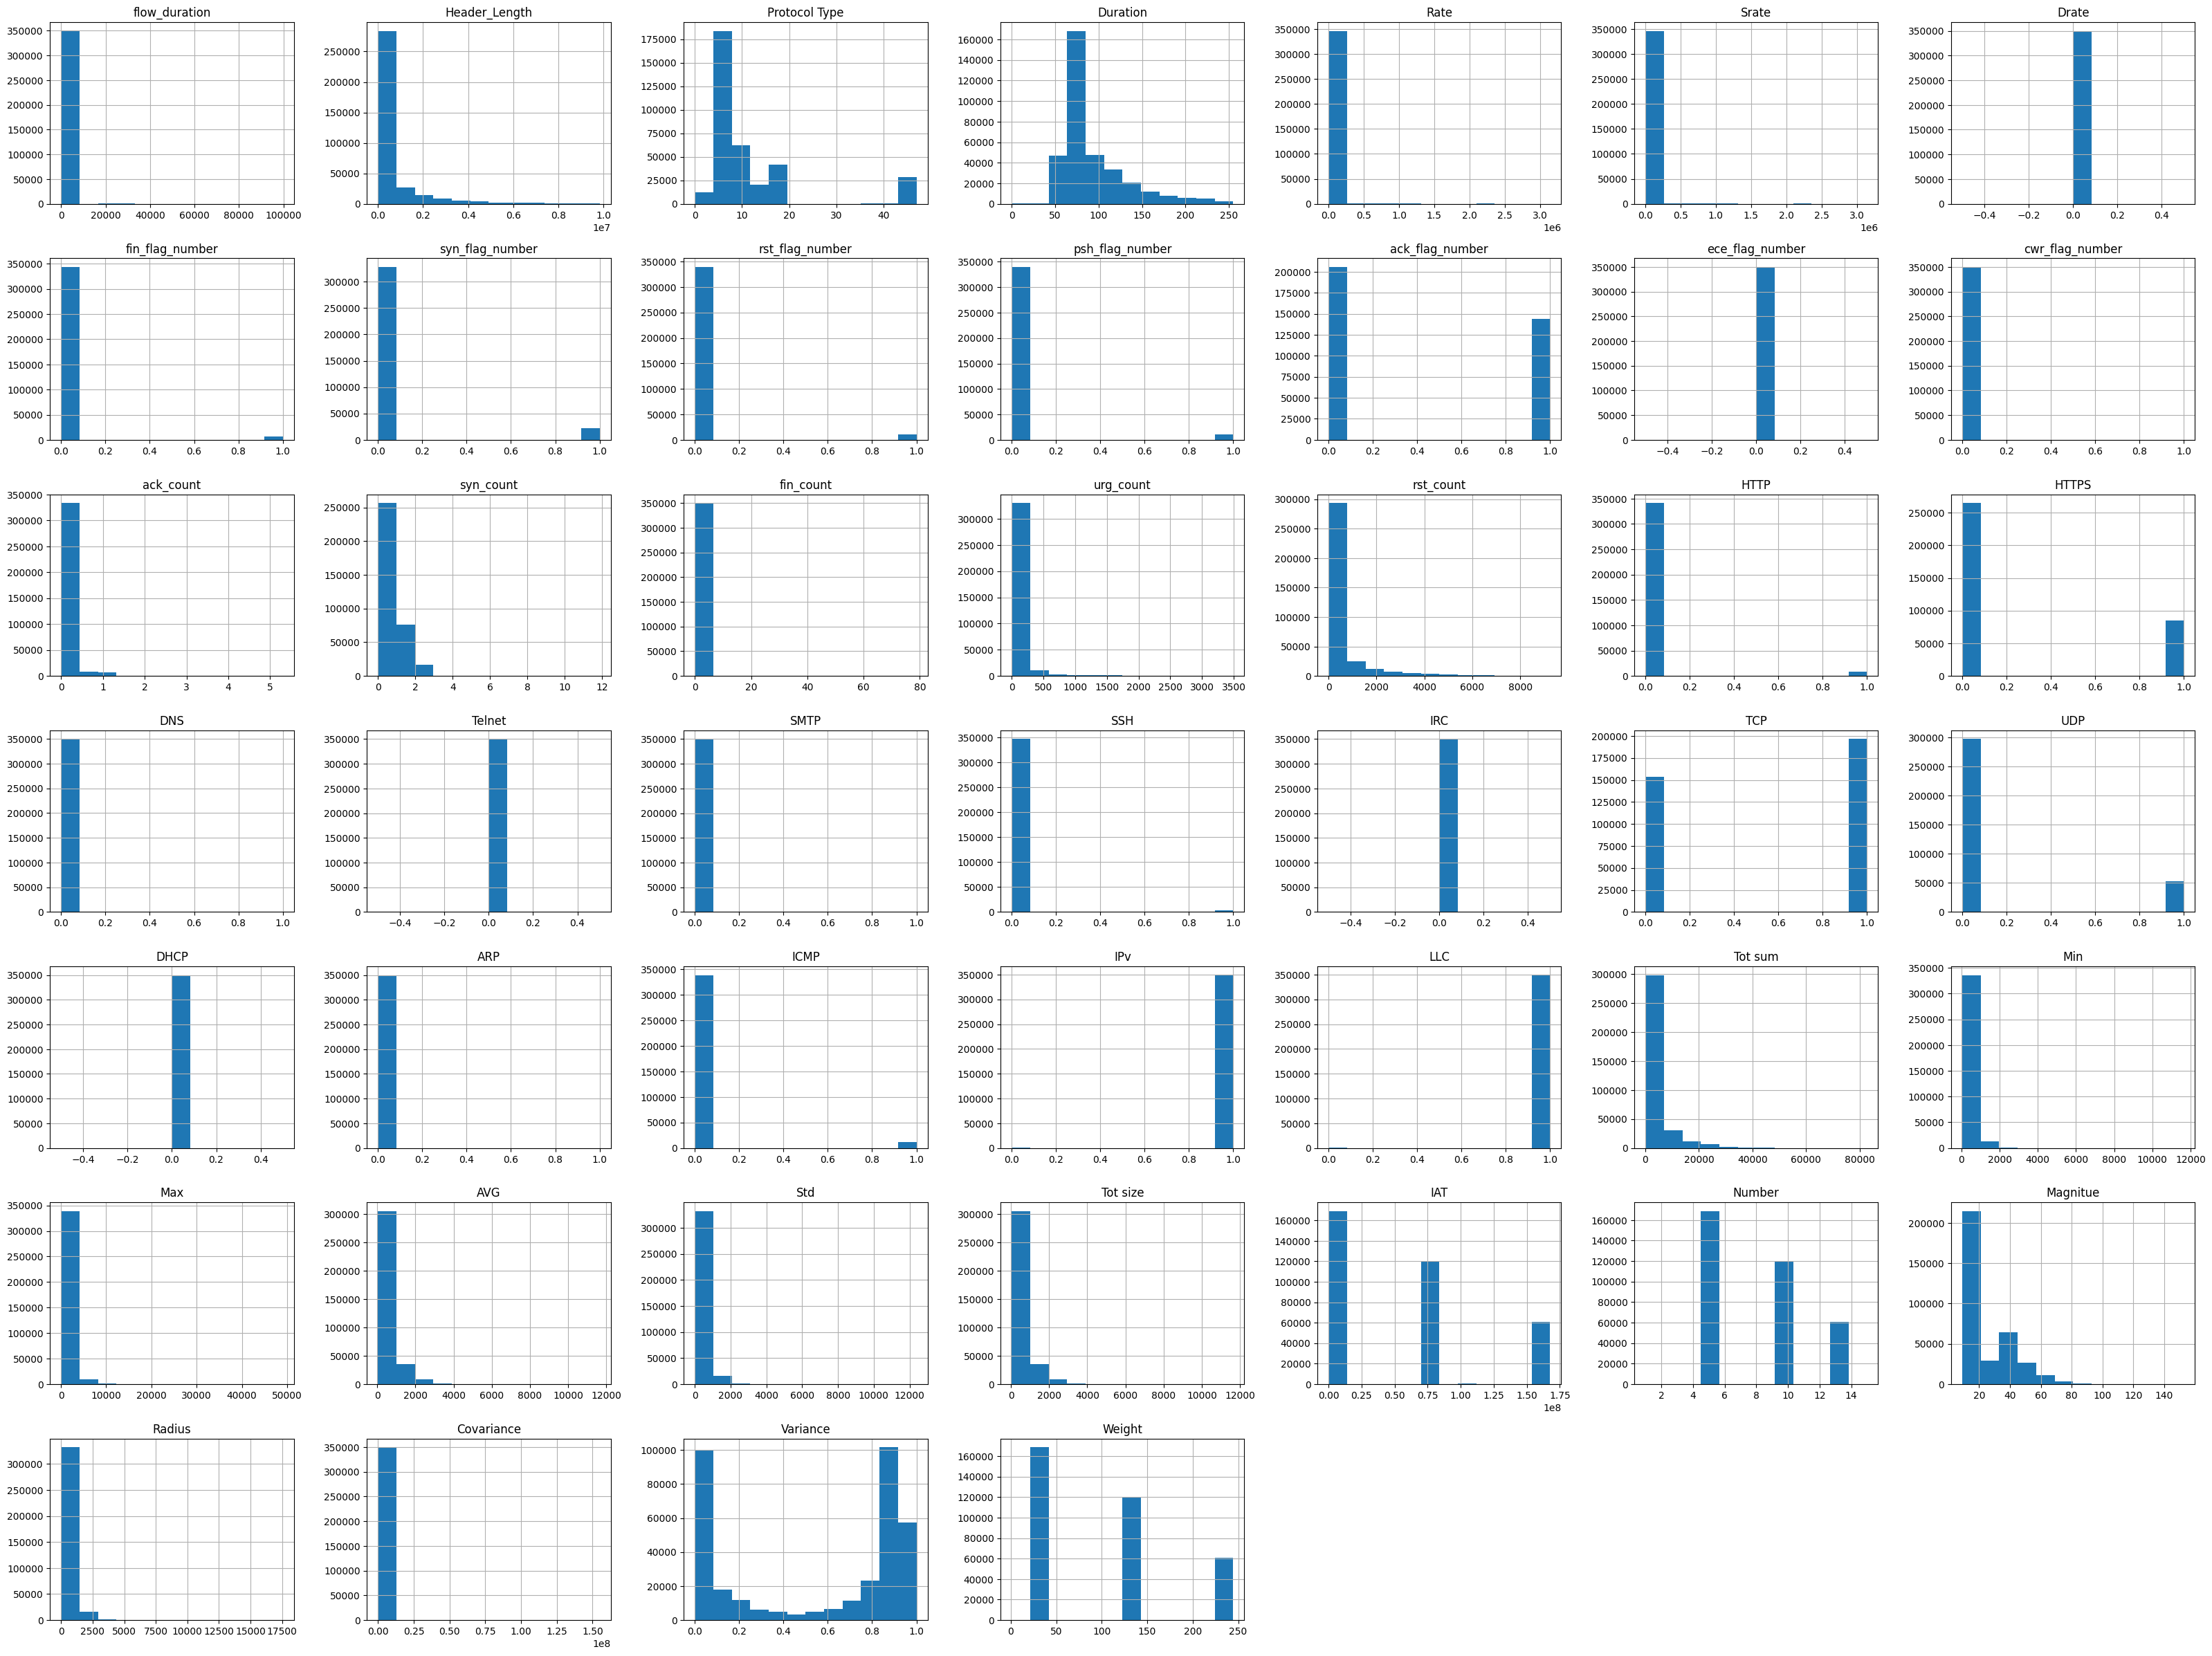

In [ ]:
df.hist(figsize=(40,30),bins = 12)
#plt.title("Features Distribution")
plt.show()

In [ ]:
# Encode labels
label_encoder = LabelEncoder()
df['label'] = label_encoder.fit_transform(df['label'])
print(df['label'].unique())

[0 1 2 3 4 6 5]


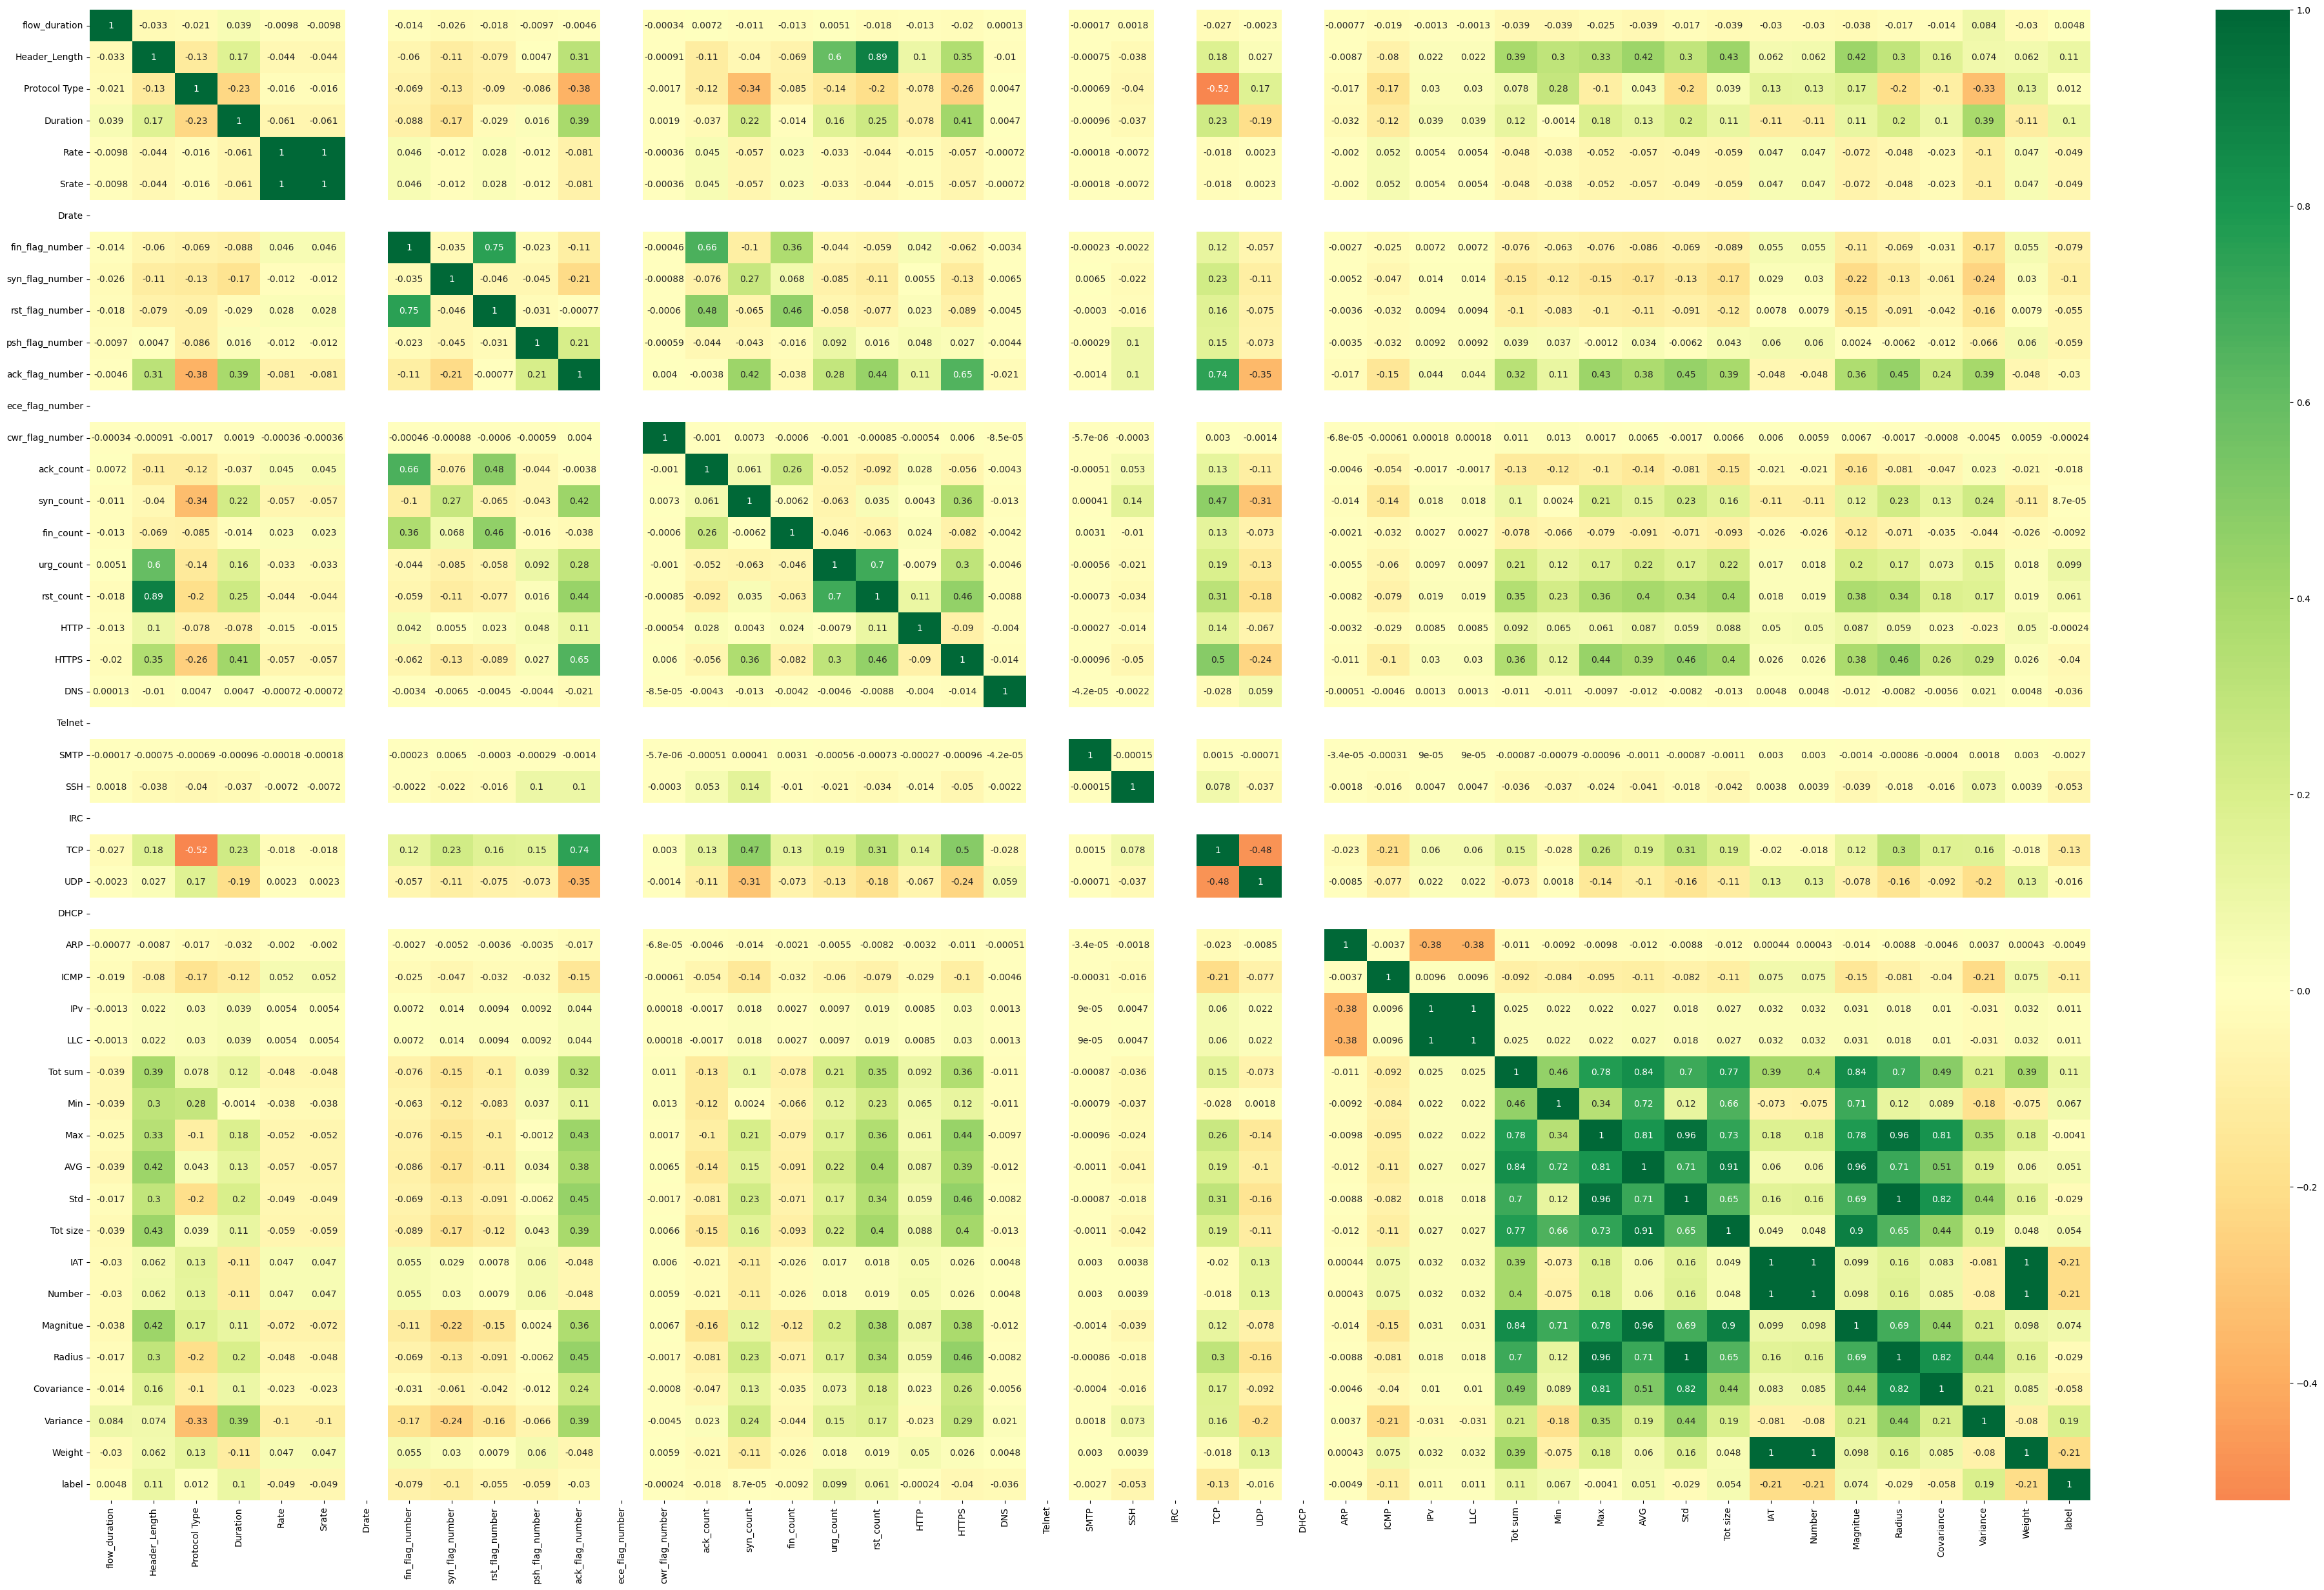

In [ ]:
plt.figure(figsize=(50,30))
p=sns.heatmap(df.corr(), annot=True,cmap='RdYlGn',center=0)

**Splitting**

In [ ]:
# Step 1: Separate features and labels (unscaled)
X = df.drop(columns=['label'])
y = df['label'].astype(int)

# Step 2: Stratified 70/15/15 split on the raw features
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)

# Step 3: Fit the scaler on the training set only, then apply it unchanged
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

print(f"Training samples  : {len(X_train)}")
print(f"Validation samples: {len(X_val)}")
print(f"Test samples      : {len(X_test)}")

Training samples  : 245058
Validation samples: 52513
Test samples      : 52513


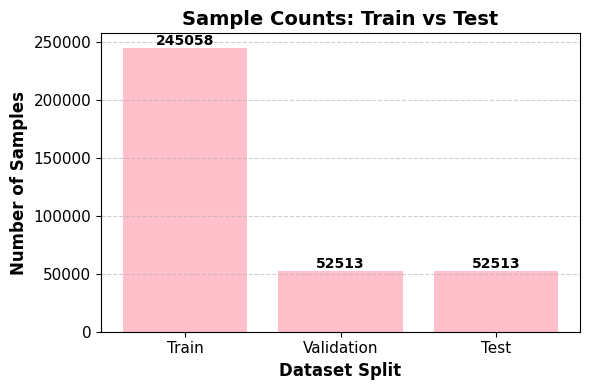

In [ ]:
import matplotlib.pyplot as plt

# Count the number of samples
train_count = len(X_train)
val_count = len(X_val)
test_count = len(X_test)

# Labels and values
labels = ['Train', 'Validation','Test']
counts = [train_count,val_count, test_count]

# Plot
plt.figure(figsize=(6, 4))
plt.bar(labels, counts, color='pink')
plt.title('Sample Counts: Train vs Test', fontsize=14, fontweight='bold')
plt.ylabel('Number of Samples', fontsize=12, fontweight='bold')
plt.xlabel('Dataset Split', fontsize=12, fontweight='bold')
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Annotate counts on bars
for i, count in enumerate(counts):
    plt.text(i, count + 1, str(count), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


Model 1

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

class NumericPatchTokenizer(layers.Layer):
    def __init__(self, n_features, patch_size, embed_dim, use_bn=True, **kwargs):
        super().__init__(**kwargs)
        self.n_features = n_features
        self.patch_size = patch_size
        self.embed_dim = embed_dim
        self.use_bn = use_bn
        if use_bn:
            # Consider switching to LayerNormalization() or do offline StandardScaler
            self.bn = layers.LayerNormalization(epsilon=1e-6)
        self.proj = layers.Dense(embed_dim)

    def call(self, x_num, training=False):
        # Safety check
        tf.debugging.assert_equal(
            tf.shape(x_num)[-1], self.n_features,
            message="Input feature dim must equal n_features"
        )
        if self.use_bn:
            x_num = self.bn(x_num, training=training)  # (B, F)
        n_patches = self.n_features // self.patch_size
        x_patched = tf.reshape(x_num, [-1, n_patches, self.patch_size])
        tokens = self.proj(x_patched)  # (B, n_patches, D)
        return tokens


class TransformerEncoderLayer(layers.Layer):
    def __init__(self, embed_dim, num_heads, mlp_dim, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.ln1 = layers.LayerNormalization(epsilon=1e-6)
        self.mha = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads, dropout=0.0  # dropout is applied to the MHSA output only (Eq. 7)
        )
        self.drop_attn = layers.Dropout(dropout)
        self.ln2 = layers.LayerNormalization(epsilon=1e-6)
        self.ffn_dense1 = layers.Dense(mlp_dim, activation="gelu")
        self.ffn_drop1 = layers.Dropout(dropout)
        self.ffn_dense2 = layers.Dense(embed_dim)
        self.ffn_drop2 = layers.Dropout(dropout)  # dropout on FFN output

    def call(self, x, training=False):
        x_norm = self.ln1(x)
        attn = self.mha(x_norm, x_norm, x_norm, training=training)
        x = x + self.drop_attn(attn, training=training)

        y = self.ln2(x)
        y = self.ffn_dense1(y)
        y = self.ffn_drop1(y, training=training)
        y = self.ffn_dense2(y)
        y = self.ffn_drop2(y, training=training)
        return x + y


class FTTransformer(layers.Layer):
    def __init__(self, n_num_features, patch_size=20, embed_dim=32,
                 n_heads=2, n_layers=1, mlp_dim=64, dropout=0.1,
                 use_cls=True, **kwargs):
        super().__init__(**kwargs)
        assert n_num_features % patch_size == 0, "n_features must be divisible by patch_size"
        self.n_patches = n_num_features // patch_size
        self.tokenizer = NumericPatchTokenizer(n_num_features, patch_size, embed_dim)
        self.use_cls = use_cls

        # Learnable positional embeddings
        self.pos_emb = self.add_weight(
            shape=(1, (self.n_patches + (1 if use_cls else 0)), embed_dim),
            initializer="zeros", trainable=True, name="pos_emb"
        )

        if use_cls:
            self.cls_token = self.add_weight(
                shape=(1, 1, embed_dim),
                initializer="random_normal",
                trainable=True,
                name="cls_token"
            )

        self.enc_layers = [
            TransformerEncoderLayer(embed_dim, n_heads, mlp_dim, dropout)
            for _ in range(n_layers)
        ]

    def call(self, x_num, training=False):
        B = tf.shape(x_num)[0]
        x = self.tokenizer(x_num, training=training)  # (B, n_patches, D)
        if self.use_cls:
            cls = tf.broadcast_to(self.cls_token, [B, 1, self.cls_token.shape[-1]])
            x = tf.concat([cls, x], axis=1)  # (B, n_patches+1, D)
        x = x + self.pos_emb  # add positions

        for layer in self.enc_layers:
            x = layer(x, training=training)
        return x


Model 2

In [ ]:

class FiLMLayer(tf.keras.layers.Layer):
    def __init__(self, units, num_features, **kwargs):
        super().__init__(**kwargs)
        self.units = units # Target output units (64)
        self.num_features = num_features # Number of input features (18)
        # Dense layers to generate gamma and beta with the same dimension as the input features (18)
        self.gamma_dense = Dense(num_features, activation=None)
        self.beta_dense = Dense(num_features, activation=None)
        # Dense layer to transform the modulated features (18) to the target output units (64)
        self.transform_dense = Dense(units, activation='relu')


    def call(self, inputs):
        # inputs shape: (batch, num_features=18)
        gamma = self.gamma_dense(inputs) # gamma shape: (batch, num_features=18)
        beta = self.beta_dense(inputs)   # beta shape: (batch, num_features=18)

        # Apply FiLM modulation element-wise
        modulated_inputs = inputs * gamma + beta # modulated_inputs shape: (batch, num_features=18)

        # Transform the modulated features to the desired output units (64) for concatenation
        film_output = self.transform_dense(modulated_inputs) # film_output shape: (batch, units=64)

        return film_output

Hybrid Model

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.layers import Dense, GRU, LayerNormalization, Dropout, Concatenate

def build_ft_gru_film_model(
    n_num_features,
    n_classes=7,
    # FT
    patch_size=20,
    embed_dim=32,
    n_heads=2,
    n_layers=1,
    ft_mlp_dim=64,
    dropout=0.1,
    use_cls=True,
    # GRU
    gru_units=64,
    bidirectional=False,
    # FiLM
    film_units=64,
    use_context=False,
    context_dim=0,
    # Head
    head_hidden_dim=128,
    head_dropout=0.3,
    model_name="FT_GRU_FiLM_Concat"
):
    assert n_num_features % patch_size == 0, "n_num_features must be divisible by patch_size"
    assert embed_dim % n_heads == 0, "embed_dim must be divisible by n_heads"

    # ----- Inputs -----
    x_num = layers.Input(shape=(n_num_features,), name="numeric_input")

    # ----- Branch A: FT Transformer Backbone -> (Bi)GRU -----
    ft_seq = FTTransformer(
        n_num_features=n_num_features,
        patch_size=patch_size,
        embed_dim=embed_dim,
        n_heads=n_heads,
        n_layers=n_layers,
        mlp_dim=ft_mlp_dim,
        dropout=dropout,
        use_cls=use_cls
    )(x_num)   # (B, T(+1), D)



    h_gru = GRU(gru_units, return_sequences=False, reset_after=True, name="gru")(ft_seq)  # unidirectional, zero initial state, final hidden state h_T

    # ----- Branch B: FiLM on the same numeric input -----

    h_film = FiLMLayer(num_features=n_num_features, units=film_units, name="film_self")(x_num)
    inputs = x_num

    # ----- Fusion -----
    fused = Concatenate(name="concat_ftgru_film")([h_gru, h_film])

    # ----- Classification Head -----
    z = LayerNormalization(name="head_norm")(fused)
    z = Dense(head_hidden_dim, activation="gelu", name="head_dense")(z)
    z = Dropout(head_dropout, name="head_dropout")(z)
    y = Dense(n_classes, activation="softmax", name="class_output")(z)

    return Model(inputs=inputs, outputs=y, name=model_name)

In [ ]:
tf.keras.utils.set_random_seed(42)

n_features = X_train.shape[1]
n_classes  = len(np.unique(y_train))

model = build_ft_gru_film_model(
    n_num_features=n_features,
    n_classes=n_classes,
    patch_size=23,
    embed_dim=96,
    n_heads=4,
    n_layers=3,
    ft_mlp_dim=192,
    dropout=0.1,
    use_cls=True,
    gru_units=128,
    film_units=128,
    head_hidden_dim=192,
    head_dropout=0.2
)

model.summary()

Model: "FT_GRU_FiLM_Concat"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ numeric_input       │ (None, 46)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_transformer      │ (None, 3, 96)     │    227,132 │ numeric_input[0]… │
│ (FTTransformer)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 128)       │     86,784 │ ft_transformer[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ film_self           │ (None, 128)       │     10,340 │ numeric_input[0]… │
│ (FiLMLayer)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_ftgru_film   │ (None, 256)       │          0 │ gru[0][0],        │
│ (Concatenate)       │                   │            │ film_self[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_norm           │ (None, 256)       │        512 │ concat_ftgru_fil… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dense (Dense)  │ (None, 192)       │     49,344 │ head_norm[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dropout        │ (None, 192)       │          0 │ head_dense[0][0]  │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 7)         │      1,351 │ head_dropout[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 375,463 (1.43 MB)

 Trainable params: 375,463 (1.43 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
!apt-get install graphviz -y

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


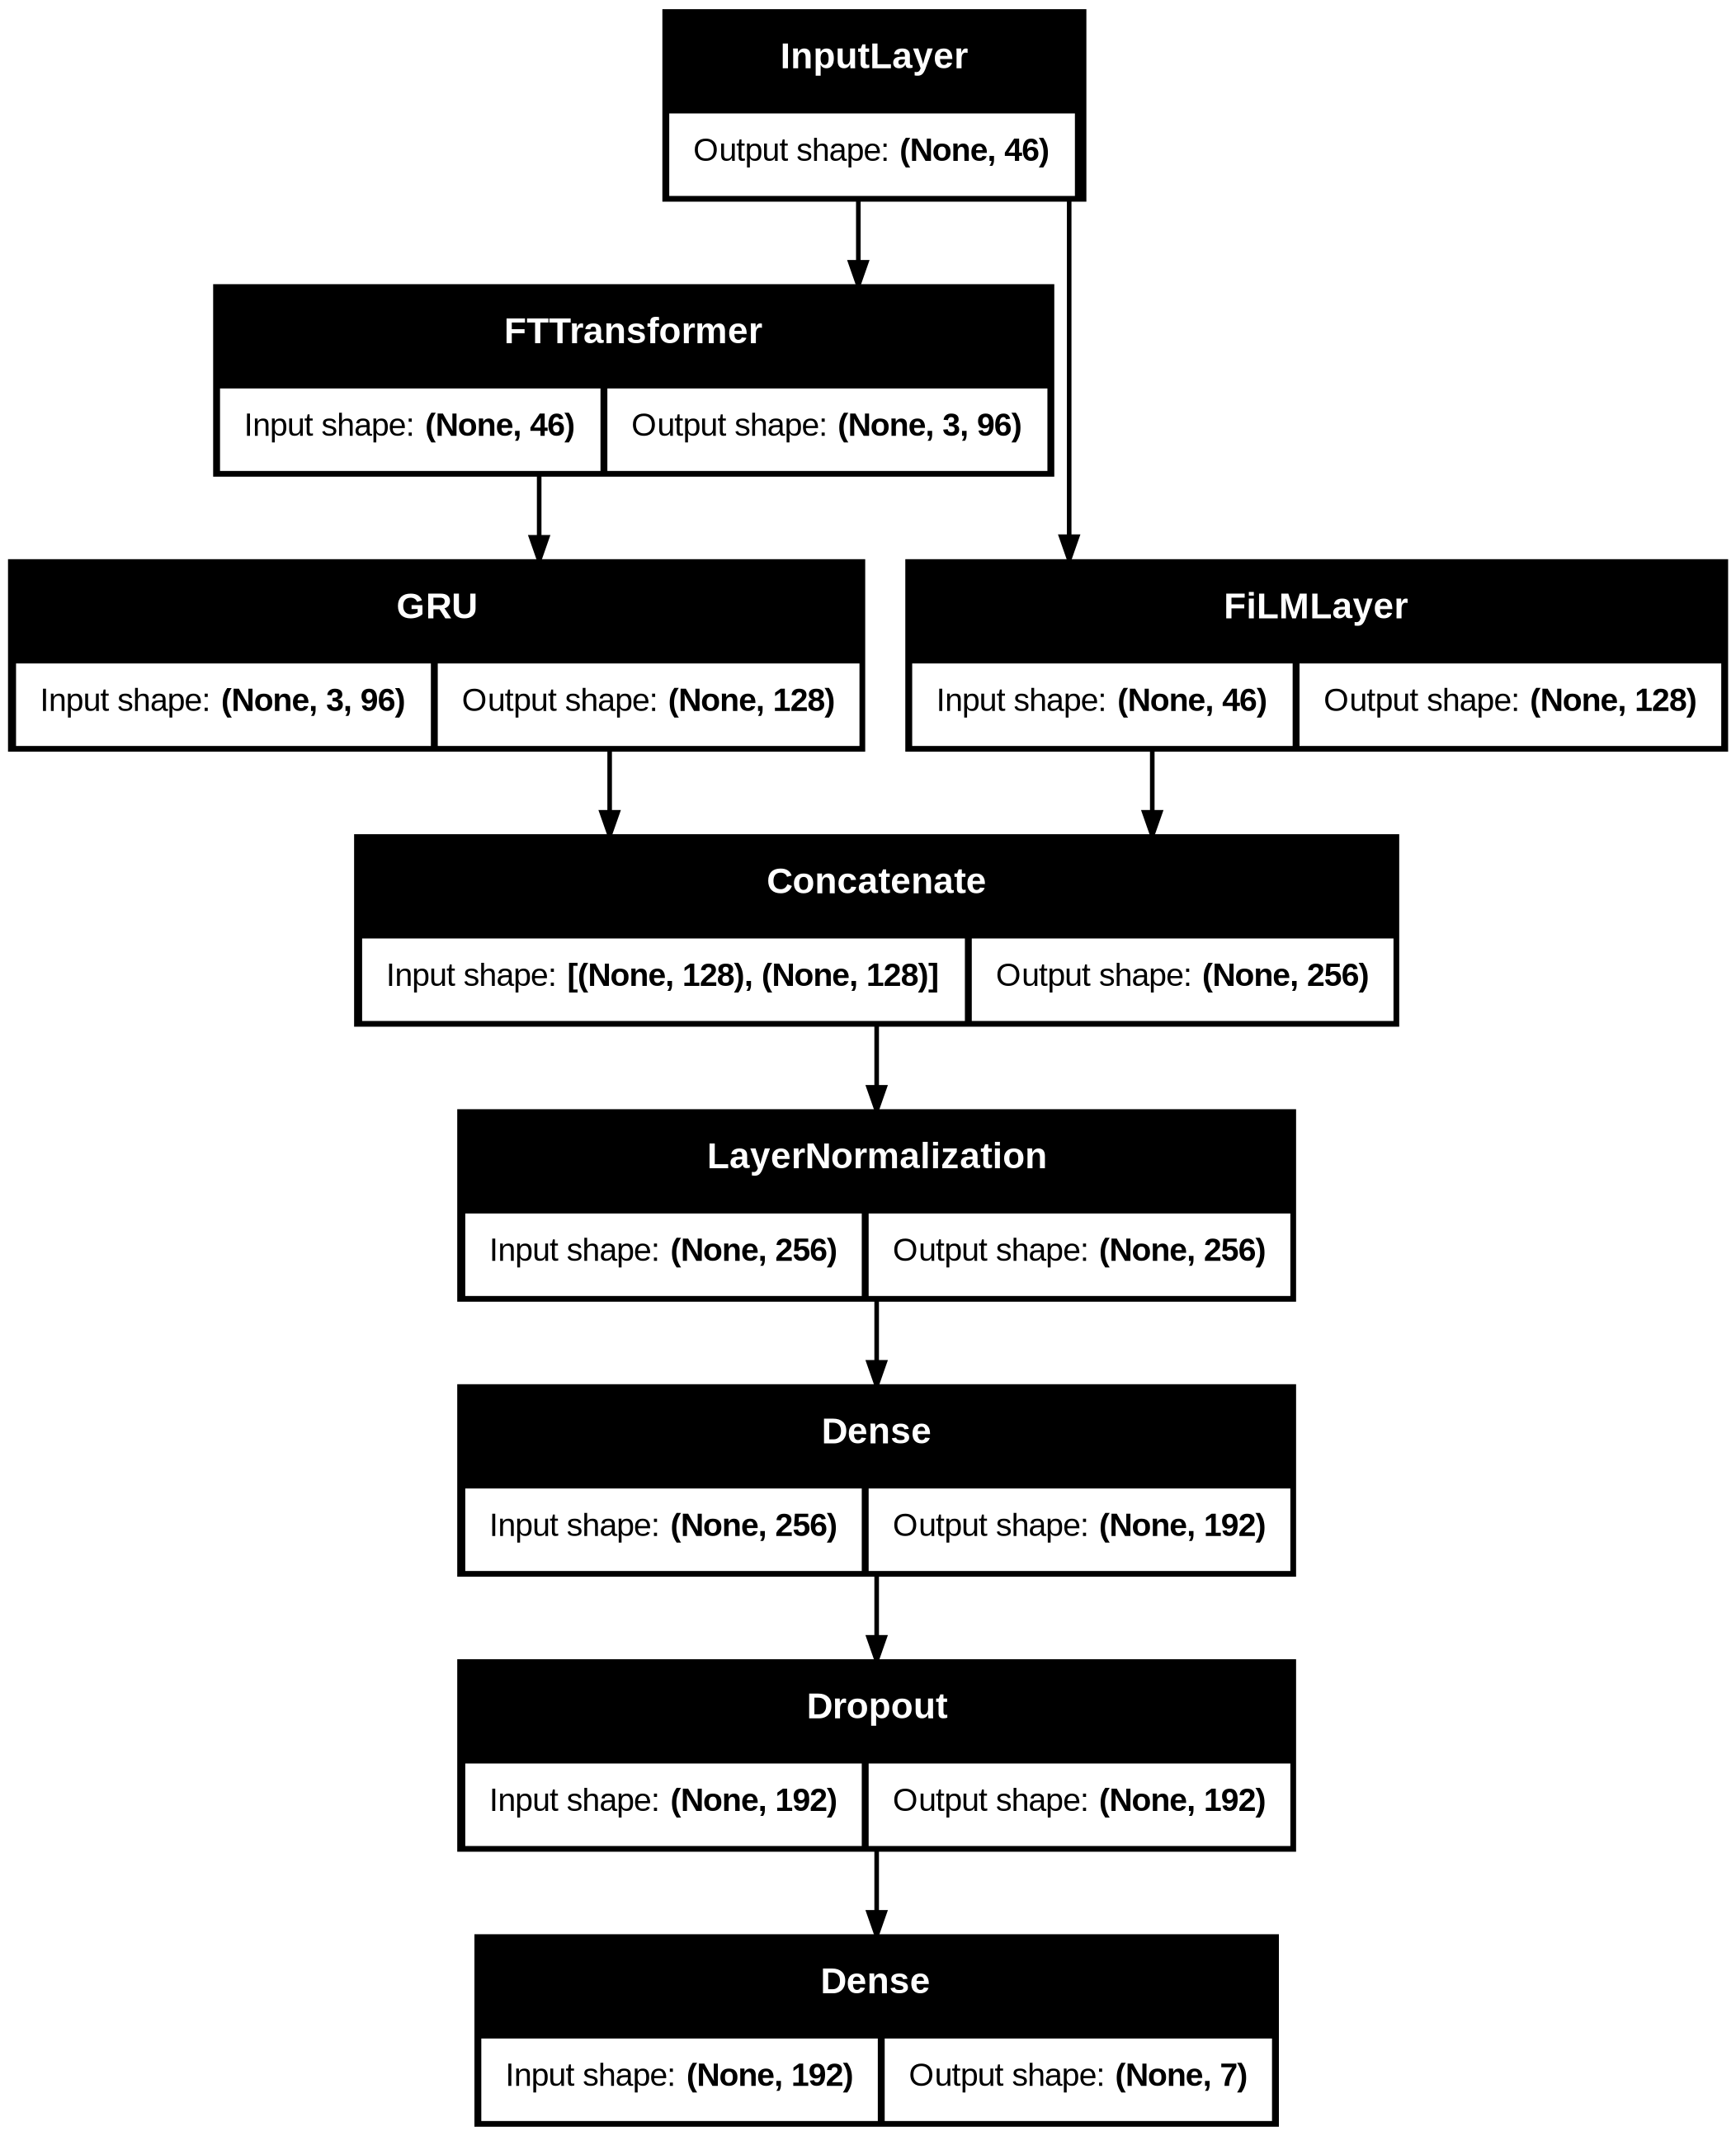

In [ ]:
plot_model(model, show_shapes=True, show_layer_names=False, to_file="model.png")


**Model Training**

In [ ]:
optimizer = tf.keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=5e-5)
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6),
]
model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])


In [ ]:
history = model.fit(
    x=X_train,
    y=y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=1024,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
240/240 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.9303 - loss: 0.1844 - val_accuracy: 0.9419 - val_loss: 0.1506 - learning_rate: 1.0000e-03
Epoch 2/100
240/240 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.9377 - loss: 0.1637 - val_accuracy: 0.9456 - val_loss: 0.1383 - learning_rate: 1.0000e-03
Epoch 3/100
240/240 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.9443 - loss: 0.1457 - val_accuracy: 0.9532 - val_loss: 0.1230 - learning_rate: 1.0000e-03
Epoch 4/100
240/240 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.9483 - loss: 0.1344 - val_accuracy: 0.9569 - val_loss: 0.1116 - learning_rate: 1.0000e-03
Epoch 5/100
240/240 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.9523 - loss: 0.1234 - val_accuracy: 0.9599 - val_loss: 0.1003 - learning_rate: 1.0000e-03
Epoch 6/100
240/240 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.9550 - loss: 0.1164 - val_accuracy: 0.9607 - val_loss: 0.1004 - learning_rate: 1.0000e-03
Epoch 7/100
240/240 ━━━━━━━━━━━━━━━━━━━━ 10s 4

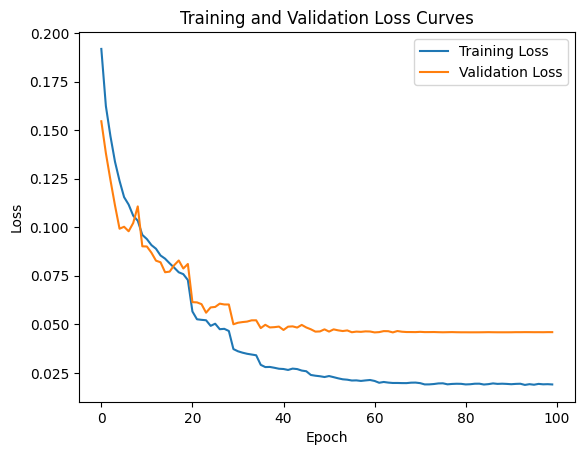

In [ ]:
import matplotlib.pyplot as plt

# Get training and validation loss history
train_loss = history.history['loss']
val_loss = history.history['val_loss']

# Plot the loss curves
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')

plt.title('Training and Validation Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

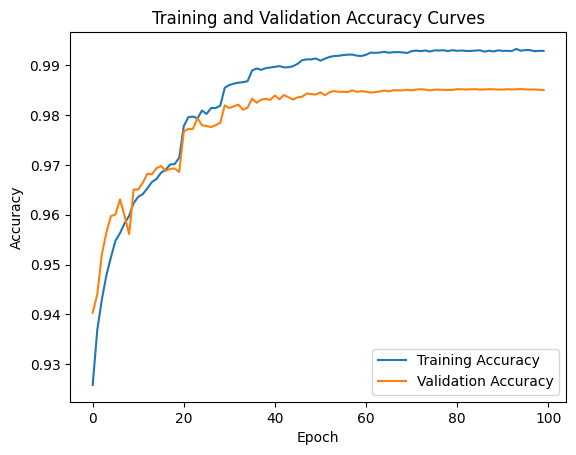

In [ ]:
# Get training and validation accuracy history
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

# Plot the accuracy curves
plt.plot(train_acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')

plt.title('Training and Validation Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

**Model Evaluation**

In [ ]:
# Evaluate quietly (no batch progress bar)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

print(f"✅ Test Accuracy: {test_acc:.2f}")


✅ Test Accuracy: 0.99


In [ ]:
class_names = [
    "BruteForce",
    "DDoS",
    "DoS",
    "Mirai",
    "Recon",
    "Spoofing",
    "Web"
]
label_map_df = pd.DataFrame({
    "label_index": range(len(class_names)),
    "label_name": class_names
})
print("\nLabel mapping:\n", label_map_df)



Label mapping:
    label_index  label_name
0            0  BruteForce
1            1        DDoS
2            2         DoS
3            3       Mirai
4            4       Recon
5            5    Spoofing
6            6         Web


In [ ]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np

# Model predictions
y_pred = model.predict(X_test)

# Convert probabilities to class labels
y_pred_classes = np.argmax(y_pred, axis=1)

# Overall evaluation metrics
accuracy = accuracy_score(y_test, y_pred_classes)

precision = precision_score(
    y_test, y_pred_classes, average='macro'
)

recall = recall_score(
    y_test, y_pred_classes, average='macro'
)

f1 = f1_score(
    y_test, y_pred_classes, average='macro'
)

# Classification report with four decimal places
target_names = [
    str(cls) for cls in label_encoder.classes_
]

report = classification_report(
    y_test,
    y_pred_classes,
    target_names=target_names,
    digits=4
)

print("Overall Evaluation Metrics:")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nDetailed Classification Report:")
print(report)


Overall Evaluation Metrics:
Accuracy  : 0.9863
Precision : 0.9857
Recall    : 0.9851
F1-Score  : 0.9854

Detailed Classification Report:

                 precision    recall  f1-score   support

0 (BruteForce)      0.9858    0.9753    0.9805      4418
1 (DDoS)            0.9796    0.9835    0.9816      8075
2 (DoS)             0.9966    0.9980    0.9973     10516
3 (Mirai)           0.9979    0.9976    0.9977      7083
4 (Recon)           0.9729    0.9751    0.9740      6584
5 (Spoofing)        0.9870    0.9873    0.9871      6994
6 (Web)             0.9803    0.9786    0.9795      8843

    accuracy                            0.9863     52513
   macro avg        0.9857    0.9851    0.9854     52513
weighted avg        0.9863    0.9863    0.9862     52513


1642/1642 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step


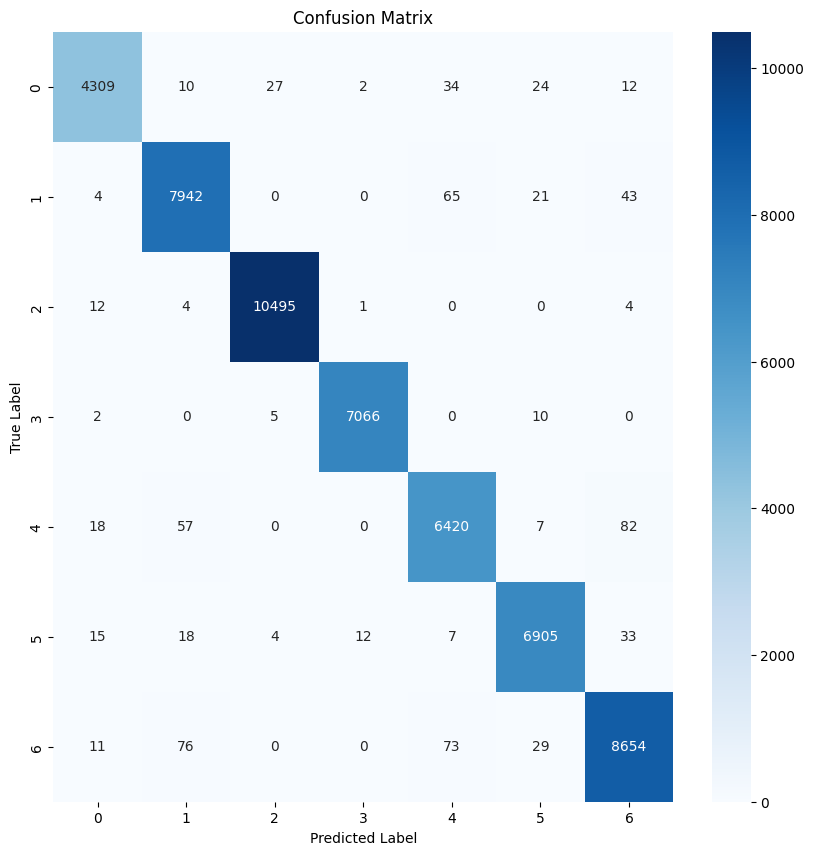

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get predictions on the test set
y_pred = model.predict(X_test)
# Assuming y_pred has shape (n_samples, n_classes)
y_pred_classes = np.argmax(y_pred, axis=1)  # Convert predictions to class labels

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

# Plot confusion matrix with labels
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_pred_probs = model.predict(X_test, verbose=0)          # (N, n_classes)
n_classes = y_pred_probs.shape[1]
y_test_bin = label_binarize(y_test, classes=range(n_classes))  # (N, n_classes)

fpr, tpr, roc_auc = {}, {}, {}
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])


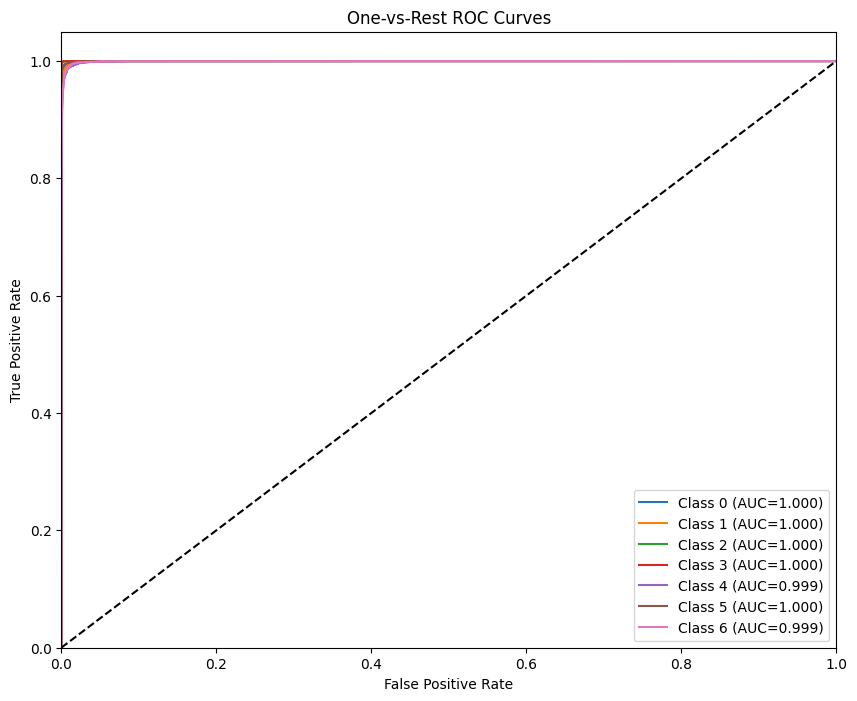

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'Class {i} (AUC={roc_auc[i]:.3f})')
plt.plot([0,1],[0,1],'k--')
plt.xlim([0,1]); plt.ylim([0,1.05])
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('One-vs-Rest ROC Curves')
plt.legend(loc='lower right'); plt.show()


In [ ]:
import os
from google.colab import files
from sklearn.metrics import classification_report

out_dir = '/content/gdrive/MyDrive/IoT_outputs'
os.makedirs(out_dir, exist_ok=True)

y_hat  = np.argmax(model.predict(X_test, verbose=0), axis=1)
y_true = y_test.values

# Predictions
pd.DataFrame({
    'original_row_index': y_test.index,
    'true_label_id': y_true,
    'true_label': [class_names[i] for i in y_true],
    'predicted_label_id': y_hat,
    'predicted_label': [class_names[i] for i in y_hat],
    'correct': y_true == y_hat,
}).to_csv(f'{out_dir}/test_predictions.csv', index=False)

# Split assignment
pd.concat([
    pd.DataFrame({'original_row_index': y_train.index, 'split': 'train'}),
    pd.DataFrame({'original_row_index': y_val.index,   'split': 'validation'}),
    pd.DataFrame({'original_row_index': y_test.index,  'split': 'test'}),
]).to_csv(f'{out_dir}/split_assignment.csv', index=False)


df.loc[y_test.index].to_csv(f'{out_dir}/test_subset_features.csv', index=False)

#  Class-wise metrics
pd.DataFrame(classification_report(y_true, y_hat, target_names=class_names,
                                   output_dict=True)).T.to_csv(f'{out_dir}/classification_report.csv')

# Download files
for f in ['test_predictions.csv', 'split_assignment.csv',
          'test_subset_features.csv', 'classification_report.csv']:
    files.download(f'{out_dir}/{f}')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import platform, sys, subprocess, json
import keras, sklearn

def cpu_model():
    try:
        with open('/proc/cpuinfo') as f:
            for line in f:
                if line.startswith('model name'):
                    return line.split(':', 1)[1].strip()
    except Exception:
        pass
    return platform.processor()

def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version',
                              '--format=csv,noheader'], capture_output=True, text=True).stdout.strip()
        return out
    except Exception:
        return 'nvidia-smi not available'

try:
    op_determinism = tf.config.experimental.is_op_determinism_enabled()
except AttributeError:
    try:
        op_determinism = tf.config.experimental.get_device_policy() is not None
    except Exception:
        op_determinism = "Unknown"

build = tf.sysconfig.get_build_info()
env = {
    'cpu_model': cpu_model(),
    'gpu_name_memory_driver': gpu_info(),
    'python': sys.version.split()[0],
    'tensorflow': tf.__version__,
    'keras': keras.__version__,
    'cuda': build.get('cuda_version'),
    'cudnn': build.get('cudnn_version'),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit_learn': sklearn.__version__,
    'random_seed': 42,
    'op_determinism_enabled': op_determinism,
}
print(json.dumps(env, indent=2))
with open(f'{out_dir}/environment.json', 'w') as f:
    json.dump(env, f, indent=2)

{
  "cpu_model": "Intel(R) Xeon(R) CPU @ 2.00GHz",
  "gpu_name_memory_driver": "Tesla T4, 15360 MiB, 580.82.07",
  "python": "3.13.16",
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "cuda": "12.5.1",
  "cudnn": "9",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scikit_learn": "1.6.1",
  "random_seed": 42,
  "op_determinism_enabled": true
}
